In [1]:
# 202431052_Anfal Ridho Hanif
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
# 202431052_Anfal Ridho Hanif
df = pd.read_csv("komikcast_data.csv")
display(df.head())
print(df.shape)
print(df.dtypes)

,judul,tipe,status,chapter_terbaru,rating
0,Reincarnated as the Archduke’s Son,Manhwa,Ongoing,56.0,9.7
1,The Supreme Demon Swordmaster,Manhua,Ongoing,60.0,10.0
2,Black Killer Whale Baby,Manhwa,Ongoing,128.0,10.0
3,Student Jo-Eun,Manhwa,Ongoing,95.0,10.0
4,The Saint Levels Up Through Necromancy,Manhwa,Ongoing,45.0,9.0


(266, 5)
judul               object
tipe                object
status              object
chapter_terbaru    float64
rating             float64
dtype: object


In [3]:
# 202431052_Anfal Ridho Hanif
df = df.dropna(subset=["chapter_terbaru", "rating"])
print("Jumlah data setelah dropna:", len(df))

Jumlah data setelah dropna: 266


In [4]:
# 202431052_Anfal Ridho Hanif
x = df[["chapter_terbaru"]]   # fitur (2 dimensi)
y = df["rating"]              # target

In [5]:
# 202431052_Anfal Ridho Hanif
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=0
)
print("Data latih:", x_train.shape[0])
print("Data uji  :", x_test.shape[0])

Data latih: 212
Data uji  : 54


In [12]:
# 202431052_Anfal Ridho Hanif
model = LinearRegression()
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

hasil = pd.DataFrame({
    "chapter_terbaru": x_test["chapter_terbaru"].values,
    "rating_aktual": y_test.values,
    "rating_prediksi": y_pred,
})
display(hasil.head(10))

,chapter_terbaru,rating_aktual,rating_prediksi
0,40.0,10.0,9.588803
1,67.0,8.0,9.589340
2,18.1,10.0,9.588367
3,284.0,9.9,9.593658
4,98.0,10.0,9.589957
5,98.0,9.5,9.589957
6,55.0,10.0,9.589102
7,6.1,10.0,9.588129
8,114.0,10.0,9.590275
9,77.0,10.0,9.589539


In [8]:
# 202431052_Anfal Ridho Hanif
koef = model.coef_
intercept = model.intercept_
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Koefisien :", koef)
print("Intercept :", intercept)
print("MSE       :", mse)
print("R2 Score  :", r2)

Koefisien : [1.98958881e-05]
Intercept : 9.588007319935606
MSE       : 0.3219241938914124
R2 Score  : -0.08830800105193659


Rating = 9.5880 + 0.000020 * chapter_terbaru


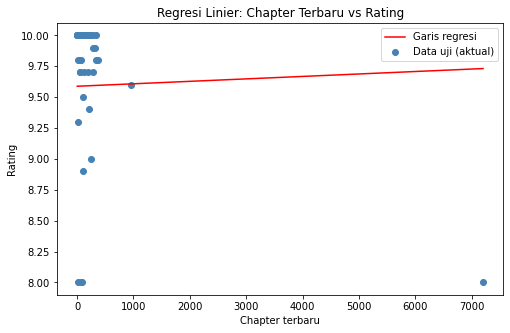

In [11]:
# 202431052_Anfal Ridho Hanif
a = intercept
b = koef[0]
print(f"Rating = {a:.4f} + {b:.6f} * chapter_terbaru")

plt.figure(figsize=(8, 5))
plt.scatter(x_test, y_test, color="steelblue", label="Data uji (aktual)")
plt.plot(x_test.sort_values("chapter_terbaru"),
         model.predict(x_test.sort_values("chapter_terbaru")),
         color="red", label="Garis regresi")
plt.xlabel("Chapter terbaru")
plt.ylabel("Rating")
plt.title("Regresi Linier: Chapter Terbaru vs Rating")
plt.legend()
plt.show()